Markets seem to have moods. Long calm stretches, when prices drift up and daily moves are small, alternate with turbulent ones, when volatility triples and prices fall. If the current mood could be recognised early enough, an investor could hold less risk in the turbulent periods and more in the calm ones. That idea is the subject of this capstone, but the real subject is the **process**: how a professional researcher turns an idea into a strategy without fooling themselves, and then into a system that runs every day.

Every safeguard of the course appears: point-in-time data and look-ahead checks (Chapter 2), volatility clustering (Chapters 1 and 3), walk-forward validation and the multiple-testing problem (Chapters 1 and 5), realistic costs (Chapter 9), and monitoring. The model is new: a **hidden Markov model**, built from scratch.

:::eli5
You cannot see the weather inside a closed room, but you can hear it: steady quiet means sunshine, loud bangs on the window mean a storm. A hidden Markov model is a way of guessing the weather from the sounds. The “weather” is the market's hidden mood (calm or turbulent), the “sounds” are daily returns, and the model knows that moods last: a storm today makes a storm tomorrow likely. The trap is to listen to the whole day's recording and then claim you knew at noon that the storm would come.
:::

## Look at the big picture: write the plan before touching the data

Professional research starts with a **research plan**, fixed before any result is seen: what is being tested, on which data, with which measures, and what will count as success. Writing it down first is the best protection against the garden of forking paths of Chapter 1, where enough small choices made after looking at results can make any idea look good. Medical trials call this **pre-registration**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm, skew, kurtosis
import json, sys, time, warnings
warnings.filterwarnings("ignore")

mpl.rc("axes", labelsize=12, titlesize=13); mpl.rc("figure", dpi=110)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
DATA = Path("datasets")
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

plan = {
    "hypothesis_1": "A 2-state Gaussian HMM on daily SPY returns, used only through its forward-filtered probabilities, "
                    "improves the risk-adjusted return of a SPY investor: exposure = 1 - P(turbulent), the rest in T-bills.",
    "hypothesis_2": "The same regime signal also improves a diversified, trend-filtered, volatility-targeted ETF portfolio (Chapters 2-4).",
    "data": "daily adjusted closes of 8 ETFs, VIX and the 3-month T-bill, 2003-01 to 2026-11 (Yahoo Finance, FRED)",
    "model_refit": "every year on an expanding window of all data before that year",
    "development_period": ["2007-01-01", "2020-12-31"], "holdout_period": ["2021-01-01", "2026-11-03"],
    "measures": ["excess-return Sharpe ratio", "maximum drawdown", "annual turnover"],
    "benchmarks": ["SPY", "SPY volatility-targeted to 16% (no leverage)", "60/40 SPY/IEF"],
    "costs_bps_per_unit_turnover": {"SPY strategy": 2, "ETF portfolio": 5},
    "tuning": "at most 9 variants (exposure floor x no-trade band), chosen on the development period only",
    "success": "development Sharpe above SPY's with a deflated Sharpe ratio > 0.95, then confirmed once on the hold-out "
               "(Sharpe not below SPY's and a smaller maximum drawdown)",
}
Path("research_plan.json").write_text(json.dumps(plan, indent=2))
print(json.dumps(plan, indent=2)[:900], "...")

{
  "hypothesis_1": "A 2-state Gaussian HMM on daily SPY returns, used only through its forward-filtered probabilities, improves the risk-adjusted return of a SPY investor: exposure = 1 - P(turbulent), the rest in T-bills.",
  "hypothesis_2": "The same regime signal also improves a diversified, trend-filtered, volatility-targeted ETF portfolio (Chapters 2-4).",
  "data": "daily adjusted closes of 8 ETFs, VIX and the 3-month T-bill, 2003-01 to 2026-11 (Yahoo Finance, FRED)",
  "model_refit": "every year on an expanding window of all data before that year",
  "development_period": [
    "2007-01-01",
    "2020-12-31"
  ],
  "holdout_period": [
    "2021-01-01",
    "2026-11-03"
  ],
  "measures": [
    "excess-return Sharpe ratio",
    "maximum drawdown",
    "annual turnover"
  ],
  "benchmarks": [
    "SPY",
    "SPY volatility-targeted to 16% (no leverage)",
    "60/40 SPY/IEF"
  ],
  " ...


:::quant
Note what the plan fixes: the **hold-out** period (almost six years) is not looked at until the very end, the number of variants to be tried is capped in advance, and success is defined on two measures, not one. A plan does not make a strategy work. It makes the conclusion believable.
:::

## Get the data

In [2]:
px = pd.read_csv(DATA / "capstone_daily.csv", index_col="date", parse_dates=True)
assets = ["SPY", "EFA", "EEM", "TLT", "IEF", "GLD", "DBC", "VNQ"]
print(px.shape, px.index[0].date(), "→", px.index[-1].date())
print(px[assets].apply(lambda c: c.first_valid_index().date()).to_string())
spy_lr = 100 * np.log(px["SPY"]).diff().dropna()              # daily log returns in percent (the HMM's input)
rets = px[assets].pct_change(fill_method=None)
rf = (px["TBILL"] / 100 / 252).ffill().shift(1)                # daily T-bill return, at the rate known the day before
DEV, HOLD = slice("2007-01-01", "2020-12-31"), slice("2021-01-01", "2026-11-03")

(6000, 10) 2003-01-02 → 2026-11-03
SPY    2003-01-02
EFA    2003-01-02
EEM    2003-04-14
TLT    2003-01-02
IEF    2003-01-02
GLD    2004-11-18
DBC    2006-02-06
VNQ    2004-09-29


:::trap
Two point-in-time checks before any modelling. (1) Adjusted prices are rebuilt by the data vendor every time a dividend is paid, so a series downloaded today differs slightly from the one available in 2010; for daily total returns of ETFs this is harmless, but for signals that use price *levels* it is a known leak. (2) The T-bill rate is published with a lag of a day; we use the previous day's value for today's interest, which is what an investor would have known.
:::

## Explore the data: does the market have moods?

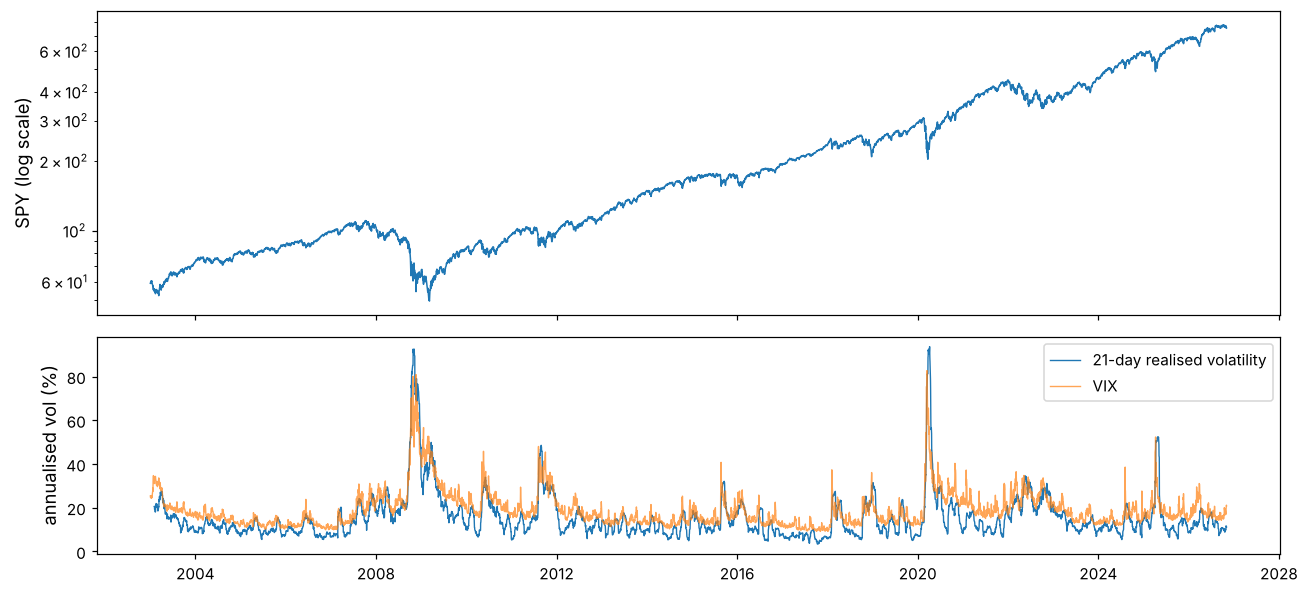

autocorrelation of |returns| at lags 1, 5, 21, 63 days: [0.31 0.35 0.22 0.12]


In [3]:
vol21 = spy_lr.rolling(21).std() * np.sqrt(252)
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
ax[0].semilogy(px["SPY"], lw=1); ax[0].set_ylabel("SPY (log scale)")
ax[1].plot(vol21, lw=0.9, label="21-day realised volatility"); ax[1].plot(px["VIX"], lw=0.9, alpha=0.7, label="VIX")
ax[1].set_ylabel("annualised vol (%)"); ax[1].legend()
save_fig("explore"); plt.show()
ac = [spy_lr.abs().autocorr(l) for l in (1, 5, 21, 63)]
print("autocorrelation of |returns| at lags 1, 5, 21, 63 days:", np.round(ac, 2))
R["ac21"] = f"{ac[2]:.2f}"; R["ac63"] = f"{ac[3]:.2f}"

![Figure 10-1. SPY since 2003 and its volatility. Calm years with volatility near 10% alternate with turbulent episodes (2008, 2011, 2020, 2022) when it triples. Turbulence comes in clusters, and the clusters last for months.](images/explore.png)

Absolute returns are still correlated 0.22 a month apart and 0.12 three months apart: volatility clusters, exactly the stylised fact of Chapter 1. A model with two persistent hidden states, one calm and one turbulent, is a natural description.

## Hidden Markov models, from scratch

:::math
**The model.** A hidden state $z_t \in \{0, 1\}$ (calm, turbulent) follows a Markov chain with transition matrix $A_{ij} = P(z_t = j \mid z_{t-1} = i)$ and initial distribution $\pi$. Given the state, the observed return is normal: $x_t \mid z_t = j \sim \mathcal N(\mu_j, \sigma_j^2)$. The expected time spent in state $j$ once entered is $1/(1 - A_{jj})$ days.

**The forward filter.** Let $\alpha_t(j) = P(z_t = j \mid x_1, \dots, x_t)$, the probability of each state given the data *up to today*. With $b_t(j) = \varphi(x_t; \mu_j, \sigma_j)$ the normal density,

$$\tilde\alpha_t(j) = b_t(j)\sum_i \alpha_{t-1}(i)A_{ij},\qquad c_t = \sum_j\tilde\alpha_t(j),\qquad \alpha_t(j) = \tilde\alpha_t(j)/c_t .$$

The normalising constants give the likelihood: $\log L = \sum_t \log c_t$. Dividing by $c_t$ at each step is the **scaling** that keeps the numbers from underflowing over thousands of days.

**The backward pass and the smoother.** With $\beta_T = 1$ and $\beta_t(i) = \sum_j A_{ij}b_{t+1}(j)\beta_{t+1}(j)/c_{t+1}$, the **smoothed** probabilities $\gamma_t(j) = P(z_t = j \mid x_1,\dots,x_T) \propto \alpha_t(j)\beta_t(j)$ use the *whole* sample, including the future of day $t$.

**Baum–Welch** (an EM algorithm) fits the parameters. The E-step computes $\gamma_t$ and the expected transitions $\xi_t(i,j) \propto \alpha_t(i)A_{ij}b_{t+1}(j)\beta_{t+1}(j)$; the M-step sets $A_{ij} \propto \sum_t\xi_t(i,j)$, $\mu_j = \sum_t\gamma_t(j)x_t / \sum_t\gamma_t(j)$ and $\sigma_j^2 = \sum_t\gamma_t(j)(x_t - \mu_j)^2/\sum_t\gamma_t(j)$. Each iteration cannot lower the likelihood.

**Viterbi** finds the single most likely state *path* by dynamic programming: $\delta_t(j) = \max_i \delta_{t-1}(i)A_{ij}\,b_t(j)$, then backtrack.
:::

In [4]:
def fit_hmm(x, iters=200, tol=1e-7):
    """Baum-Welch for a 2-state Gaussian HMM; state 0 = calm (lower volatility)"""
    n = len(x)
    mu = np.quantile(x, [0.3, 0.7]); sd = np.std(x) * np.array([0.6, 1.8])
    A = np.array([[0.95, 0.05], [0.05, 0.95]]); pi = np.array([0.5, 0.5]); ll_old = -np.inf
    for it in range(iters):
        B = norm.pdf(x[:, None], mu, sd)
        al = np.zeros((n, 2)); c = np.zeros(n)
        al[0] = pi * B[0]; c[0] = al[0].sum(); al[0] /= c[0]
        for t in range(1, n):                                     # forward
            al[t] = (al[t - 1] @ A) * B[t]; c[t] = al[t].sum(); al[t] /= c[t]
        be = np.ones((n, 2))
        for t in range(n - 2, -1, -1):                            # backward
            be[t] = (A @ (B[t + 1] * be[t + 1])) / c[t + 1]
        g = al * be; g /= g.sum(axis=1, keepdims=True)             # E-step
        xi = al[:-1, :, None] * A[None] * (B[1:] * be[1:])[:, None, :] / c[1:, None, None]
        A = xi.sum(axis=0); A /= A.sum(axis=1, keepdims=True); pi = g[0]      # M-step
        w = g / g.sum(axis=0); mu = (w * x[:, None]).sum(axis=0); sd = np.sqrt((w * (x[:, None] - mu)**2).sum(axis=0))
        ll = np.log(c).sum()
        if ll - ll_old < tol:
            break
        ll_old = ll
    o = np.argsort(sd)
    return dict(mu=mu[o], sd=sd[o], A=A[np.ix_(o, o)], pi=pi[o], loglik=ll, iterations=it + 1)

def forward_filter(x, p):
    """P(state | data up to t) for every t"""
    B = norm.pdf(x[:, None], p["mu"], p["sd"]); al = np.zeros((len(x), 2))
    a = p["pi"] * B[0]; al[0] = a / a.sum()
    for t in range(1, len(x)):
        a = (al[t - 1] @ p["A"]) * B[t]; al[t] = a / a.sum()
    return al

def smoother(x, p):
    """P(state | all data): uses the future"""
    B = norm.pdf(x[:, None], p["mu"], p["sd"]); n = len(x)
    al = np.zeros((n, 2)); c = np.zeros(n); a = p["pi"] * B[0]; c[0] = a.sum(); al[0] = a / c[0]
    for t in range(1, n):
        a = (al[t - 1] @ p["A"]) * B[t]; c[t] = a.sum(); al[t] = a / c[t]
    be = np.ones((n, 2))
    for t in range(n - 2, -1, -1):
        be[t] = (p["A"] @ (B[t + 1] * be[t + 1])) / c[t + 1]
    g = al * be; return g / g.sum(axis=1, keepdims=True)

def viterbi(x, p):
    logB = norm.logpdf(x[:, None], p["mu"], p["sd"]); logA = np.log(p["A"]); n = len(x)
    delta = np.log(p["pi"]) + logB[0]; back = np.zeros((n, 2), int)
    for t in range(1, n):
        s = delta[:, None] + logA; back[t] = s.argmax(axis=0); delta = s.max(axis=0) + logB[t]
    z = np.zeros(n, int); z[-1] = delta.argmax()
    for t in range(n - 1, 0, -1):
        z[t - 1] = back[t, z[t]]
    return z

First, the test every from-scratch estimator must pass: simulate data from known parameters and check that the fit recovers them.

In [5]:
true = dict(mu=np.array([0.06, -0.10]), sd=np.array([0.7, 2.0]), A=np.array([[0.99, 0.01], [0.03, 0.97]]), pi=np.array([1.0, 0.0]))
rg = np.random.default_rng(10); n_sim = 5000; z = np.zeros(n_sim, int)
for t in range(1, n_sim):
    z[t] = rg.random() < true["A"][z[t - 1], 1]
x_sim = rg.normal(true["mu"][z], true["sd"][z])
t0 = time.perf_counter(); est = fit_hmm(x_sim); t_fit = time.perf_counter() - t0
print(pd.DataFrame({"true": [*true["mu"], *true["sd"], true["A"][0, 0], true["A"][1, 1]],
                    "estimated": [*est["mu"], *est["sd"], est["A"][0, 0], est["A"][1, 1]]},
                   index=["mu calm", "mu turbulent", "sd calm", "sd turbulent", "A calm->calm", "A turb->turb"]).round(3))
acc_f = ((forward_filter(x_sim, est)[:, 1] > 0.5) == z).mean(); acc_s = ((smoother(x_sim, est)[:, 1] > 0.5) == z).mean()
acc_v = (viterbi(x_sim, est) == z).mean()
print(f"fitted in {est['iterations']} iterations ({t_fit:.1f} s); states classified correctly: filter {acc_f:.1%}, smoother {acc_s:.1%}, Viterbi {acc_v:.1%}")
R.update(acc_f=f"{acc_f:.1%}", acc_s=f"{acc_s:.1%}")

              true  estimated
mu calm       0.06      0.056
mu turbulent -0.10     -0.141
sd calm       0.70      0.707
sd turbulent  2.00      1.924
A calm->calm  0.99      0.989
A turb->turb  0.97      0.964
fitted in 14 iterations (0.8 s); states classified correctly: filter 93.7%, smoother 97.3%, Viterbi 96.7%


The estimates are close to the truth. Notice the classification accuracy: the smoother, which looks at the future, identifies the hidden state more often (97.3%) than the filter (93.7%), which only uses the past. That gap is the subject of the next section.

### Fitting the model to SPY

In [6]:
p_dev = fit_hmm(spy_lr.loc[:"2020"].to_numpy())
desc = pd.DataFrame({"daily mean (%)": p_dev["mu"], "annualised vol (%)": p_dev["sd"] * np.sqrt(252),
                     "stay probability": np.diag(p_dev["A"]), "expected duration (days)": 1 / (1 - np.diag(p_dev["A"]))},
                    index=["calm", "turbulent"])
print(desc.round(3))
R.update(vol_calm=f"{desc.iloc[0, 1]:.0f}", vol_turb=f"{desc.iloc[1, 1]:.0f}", dur_calm=f"{desc.iloc[0, 3]:.0f}", dur_turb=f"{desc.iloc[1, 3]:.0f}")

           daily mean (%)  annualised vol (%)  stay probability  \
calm                0.090              10.749             0.988   
turbulent          -0.127              34.241             0.961   

           expected duration (days)  
calm                         86.076  
turbulent                    25.599  


On the development data the model finds a calm state with annualised volatility of 11% that lasts 86 trading days on average, and a turbulent state with 34% that lasts about 26 days, with a negative mean. The model was told nothing about crises; it found them from the returns alone.

## The look-ahead trap: filtered versus smoothed

The smoothed probabilities of a model fitted on all the data are what most regime-detection tutorials plot, and they look wonderful: the turbulent state switches on right at the start of each crash. But on 15 September 2008 nobody knew the rest of 2008. A trader can only use the **filtered** probability, from a model fitted on data available at the time.

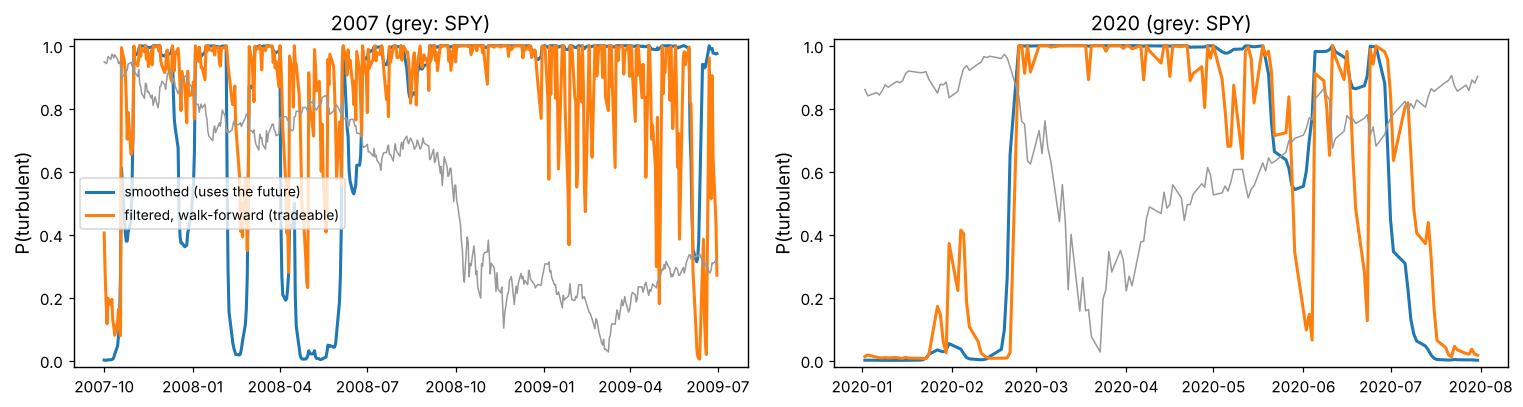

In [7]:
p_full = fit_hmm(spy_lr.to_numpy())                            # fitted on everything, including the hold-out
smooth = pd.Series(smoother(spy_lr.to_numpy(), p_full)[:, 1], index=spy_lr.index)

filt = pd.Series(np.nan, index=spy_lr.index)                   # walk-forward: refit each January on all earlier data
fits = {}
for yr in range(2007, 2027):
    fits[yr] = fit_hmm(spy_lr.loc[:f"{yr - 1}"].to_numpy())
    al = forward_filter(spy_lr.loc[:f"{yr}"].to_numpy(), fits[yr])
    filt.loc[f"{yr}"] = al[-len(spy_lr.loc[f"{yr}"]):, 1]
filt = filt.dropna()

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, (a0, a1) in zip(ax, [("2007-10-01", "2009-06-30"), ("2020-01-01", "2020-07-31")]):
    a2 = a.twinx(); a2.plot(px["SPY"].loc[a0:a1], color="0.6", lw=1); a2.set_yticks([])
    a.plot(smooth.loc[a0:a1], lw=2, label="smoothed (uses the future)"); a.plot(filt.loc[a0:a1], lw=2, label="filtered, walk-forward (tradeable)")
    a.set_ylabel("P(turbulent)"); a.set_ylim(-0.02, 1.02); a.set_title(f"{a0[:4]} (grey: SPY)")
ax[0].legend(loc="center left", fontsize=9)
save_fig("filter_vs_smoother"); plt.show()

![Figure 10-2. The probability of the turbulent state in 2007–09 and 2020. The smoothed probability (blue) stays steady through each crisis and switches off cleanly at the end, because it has seen what came next. The filtered probability (orange) can only react to returns that have already happened: it flickers down on every calm-looking day inside a crisis and recognises the end of turbulence only after the rebound has begun.](images/filter_vs_smoother.png)

How much does the difference matter? Trade both: hold SPY with exposure $1 - P(\text{turbulent})$ decided at today's close, the rest in T-bills, 2 basis points of cost per unit of turnover.

In [8]:
def spy_regime(prob, floor=0.0, band=0.0, cost_bps=2.0):
    """exposure = 1 - (1 - floor) * prob, changed only when it moves by more than band; returns daily net returns"""
    r_ = rets["SPY"].reindex(prob.index); target = (1 - (1 - floor) * prob).to_numpy(); e = np.empty(len(target)); cur = target[0]
    for i, t in enumerate(target):
        if abs(t - cur) > band:
            cur = t
        e[i] = cur
    e = pd.Series(e, index=prob.index); held = e.shift(1).fillna(0)          # decided at the close, earns the next day
    rf_ = rf.reindex(prob.index)
    return held * r_ + (1 - held) * rf_ - e.diff().abs().shift(1).fillna(0) * cost_bps / 1e4, e

def perf(x):
    x = x.dropna(); ex = x - rf.reindex(x.index); eq = (1 + x).cumprod()
    return pd.Series({"annual return": x.mean() * 252, "vol": x.std() * np.sqrt(252), "Sharpe (excess)": ex.mean() / ex.std() * np.sqrt(252),
                      "max drawdown": (eq / eq.cummax() - 1).min()})

cheat, _ = spy_regime(smooth.loc["2007":]); honest, _ = spy_regime(filt)
trap = pd.DataFrame({"SPY": perf(rets["SPY"].loc[DEV]), "smoothed, full-sample fit (look-ahead)": perf(cheat.loc[DEV]),
                     "filtered, walk-forward": perf(honest.loc[DEV])}).T
print(trap.round(3))
R.update(cheat_sh=f"{trap.iloc[1, 2]:.2f}", honest_sh=f"{trap.iloc[2, 2]:.2f}", spy_sh_dev=f"{trap.iloc[0, 2]:.2f}")

                                        annual return    vol  Sharpe (excess)  \
SPY                                             0.111  0.206            0.497   
smoothed, full-sample fit (look-ahead)          0.160  0.088            1.721   
filtered, walk-forward                          0.086  0.102            0.755   

                                        max drawdown  
SPY                                           -0.552  
smoothed, full-sample fit (look-ahead)        -0.083  
filtered, walk-forward                        -0.138  


With the look-ahead, the regime strategy has a Sharpe ratio of 1.72 over 2007–2020; honestly, 0.76. More than half of the “edge” of the cheating version is information from the future. If a regime-switching backtest you read about looks too good, check which probabilities it used.

## Select and train: the walk-forward backtest

Now the honest version, compared with the benchmarks of the research plan on the development period only. The volatility-targeted benchmark is the simplest possible competitor: exposure $\min(1, 16\%/\hat\sigma_{63})$, using the trailing 63-day volatility (Chapter 3). If the HMM cannot beat that, it is not worth its complexity.

In [9]:
vol63 = rets["SPY"].rolling(63).std() * np.sqrt(252)
e_vt = (0.16 / vol63).clip(upper=1.0).loc["2007":]
vt = e_vt.shift(1) * rets["SPY"].loc["2007":] + (1 - e_vt.shift(1)) * rf.loc["2007":] - e_vt.diff().abs().shift(1) * 2e-4
b6040 = 0.6 * rets["SPY"] + 0.4 * rets["IEF"]
dev_tab = pd.DataFrame({"SPY": perf(rets["SPY"].loc[DEV]), "SPY vol-targeted": perf(vt.loc[DEV]), "60/40": perf(b6040.loc[DEV]),
                        "SPY regime (HMM)": perf(honest.loc[DEV])}).T
print(dev_tab.round(3))
R.update(vt_sh=f"{dev_tab.loc['SPY vol-targeted', 'Sharpe (excess)']:.2f}", hmm_dd=f"{dev_tab.loc['SPY regime (HMM)', 'max drawdown']:.0%}",
         spy_dd=f"{dev_tab.loc['SPY', 'max drawdown']:.0%}", vt_dd=f"{dev_tab.loc['SPY vol-targeted', 'max drawdown']:.0%}")

                  annual return    vol  Sharpe (excess)  max drawdown
SPY                       0.111  0.206            0.497        -0.552
SPY vol-targeted          0.092  0.143            0.587        -0.342
60/40                     0.088  0.115            0.695        -0.314
SPY regime (HMM)          0.086  0.102            0.755        -0.138


On the development period the regime strategy beats SPY (Sharpe 0.76 against 0.50) and the volatility-targeted benchmark (0.59), with a maximum drawdown of -14% against -55% for SPY and -34% for volatility targeting. Hypothesis 1 survives its first test.

### Hypothesis 2: does the signal add to a diversified portfolio?

The second hypothesis asks whether the same signal helps the kind of portfolio built in Chapters 2–4: inverse-volatility weights across eight ETFs, each asset held only above its 200-day average (trend), scaled weekly to 10% volatility, with 5 basis points of costs. A 2×2 test separates the two ways of de-risking: volatility targeting and the regime signal.

In [10]:
def etf_portfolio(vol_target=True, regime=False, target=0.10, reb=5, cost_bps=5.0):
    R_ = rets.loc["2006-02-07":].fillna(0); Rv = R_.to_numpy()
    iv = 1 / (R_.rolling(63).std() * np.sqrt(252)); w = iv.div(iv.sum(axis=1), axis=0)
    lvl = (1 + R_).cumprod(); w = w * (lvl > lvl.rolling(200).mean())
    p_ = filt.reindex(R_.index).fillna(0.0).to_numpy(); W = np.zeros(R_.shape); cur = np.zeros(len(assets))
    for i in range(200, len(R_)):
        if (i - 200) % reb == 0:
            wi = w.iloc[i].to_numpy()
            if vol_target:
                C = np.cov(Rv[i - 62:i + 1].T) * 252; pv = np.sqrt(wi @ C @ wi); wi = wi * (min(1.5, target / pv) if pv > 0 else 0)
            if regime:
                wi = wi * (1 - p_[i])
            cur = wi
        W[i] = cur
    W = pd.DataFrame(W, index=R_.index, columns=assets); held = W.shift(1).fillna(0)
    net = (held * R_).sum(axis=1) + (1 - held.sum(axis=1)) * rf.reindex(R_.index) - W.diff().abs().sum(axis=1).shift(1).fillna(0) * cost_bps / 1e4
    return net.loc["2007":]

h2 = {(vt_, rg_): perf(etf_portfolio(vt_, rg_).loc[DEV]) for vt_ in (False, True) for rg_ in (False, True)}
h2_tab = pd.DataFrame(h2).T; h2_tab.index = [f"vol target {'on' if a else 'off'}, regime {'on' if b else 'off'}" for a, b in h2_tab.index]
print(h2_tab.round(3))
R.update(h2_base=f"{h2_tab.iloc[2, 2]:.2f}", h2_reg=f"{h2_tab.iloc[3, 2]:.2f}", h2_novt_reg=f"{h2_tab.iloc[1, 2]:.2f}", h2_novt=f"{h2_tab.iloc[0, 2]:.2f}")

                            annual return    vol  Sharpe (excess)  \
vol target off, regime off          0.054  0.060            0.771   
vol target off, regime on           0.030  0.046            0.465   
vol target on, regime off           0.070  0.081            0.757   
vol target on, regime on            0.037  0.062            0.459   

                            max drawdown  
vol target off, regime off        -0.091  
vol target off, regime on         -0.092  
vol target on, regime off         -0.107  
vol target on, regime on          -0.136  


Hypothesis 2 fails on the development period, decisively: adding the regime signal to the volatility-targeted ETF portfolio lowers its Sharpe ratio from 0.76 to 0.46, and without volatility targeting from 0.77 to 0.47. The diversified portfolio's trend filter and bond holdings already move it out of trouble in turbulent equity markets; scaling it down further by an *equity* regime signal mostly removes exposure to the bonds and gold that were protecting it. Following the plan, hypothesis 2 is rejected here and never touches the hold-out.

:::note
A rejected hypothesis is a result, not a failure. Most research ideas fail, and a pipeline that can reject them cheaply and honestly is worth more than any single strategy. Write the rejection into the research report so that nobody tests the same idea again in six months and “discovers” it with a different parameter.
:::

## Fine-tune the model, honestly

The plan allowed nine variants: the exposure in the turbulent state (`floor` 0, 0.25 or 0.5 instead of 0) and a no-trade **band** (0, 0.1 or 0.2) that ignores small changes in exposure to save costs. All are evaluated on the development period only.

In [11]:
grid = []
for floor in [0.0, 0.25, 0.5]:
    for band in [0.0, 0.1, 0.2]:
        net, e = spy_regime(filt, floor, band)
        d_ = net.loc[DEV]; ex = d_ - rf.reindex(d_.index)
        grid.append(dict(floor=floor, band=band, sharpe=ex.mean() / ex.std() * np.sqrt(252), sr_daily=ex.mean() / ex.std(),
                         maxdd=perf(d_)["max drawdown"], turnover=e.loc[DEV].diff().abs().sum() / (len(d_) / 252), returns=ex))
grid = pd.DataFrame(grid)
print(grid.drop(columns="returns").round(3).to_string(index=False))
best = grid.loc[grid["sharpe"].idxmax()]
print(f"chosen: floor {best['floor']}, band {best['band']} (development Sharpe {best['sharpe']:.3f})")
R.update(grid_min=f"{grid['sharpe'].min():.2f}", grid_max=f"{grid['sharpe'].max():.2f}", best_floor=f"{best['floor']:g}", best_band=f"{best['band']:g}")

 floor  band  sharpe  sr_daily  maxdd  turnover
  0.00   0.0   0.755     0.048 -0.138    13.984
  0.00   0.1   0.756     0.048 -0.133    11.338
  0.00   0.2   0.737     0.046 -0.154     9.049
  0.25   0.0   0.725     0.046 -0.246    10.488
  0.25   0.1   0.727     0.046 -0.227     7.791
  0.25   0.2   0.743     0.047 -0.208     5.639
  0.50   0.0   0.642     0.040 -0.357     6.992
  0.50   0.1   0.633     0.040 -0.346     4.525
  0.50   0.2   0.622     0.039 -0.317     2.837
chosen: floor 0.0, band 0.1 (development Sharpe 0.756)


The nine Sharpe ratios range only from 0.62 to 0.76: the result does not hinge on a lucky parameter, a good sign. We choose the best (floor 0, band 0.1) and correct for having chosen it.

:::math
The **deflated Sharpe ratio** (Bailey and López de Prado, 2014; Chapter 5) asks how likely the chosen strategy's true Sharpe ratio is above zero, after accounting for the $N$ trials, the sample length $T$, and the skewness $\gamma_3$ and kurtosis $\gamma_4$ of its returns. With $\widehat{SR}$ the daily Sharpe ratio of the chosen variant, the benchmark that the best of $N$ useless strategies would reach is

$$SR_0 = \sqrt{\mathrm{Var}[\widehat{SR}_n]}\left[(1-\gamma)\,\Phi^{-1}\!\left(1 - \tfrac1N\right) + \gamma\,\Phi^{-1}\!\left(1 - \tfrac{1}{Ne}\right)\right],\quad\gamma \approx 0.5772,$$

and $\text{DSR} = \Phi\!\left(\dfrac{(\widehat{SR} - SR_0)\sqrt{T-1}}{\sqrt{1 - \gamma_3\widehat{SR} + \frac{\gamma_4 - 1}{4}\widehat{SR}^2}}\right)$.
:::

In [12]:
def deflated_sharpe(ret, trial_srs):
    sr = ret.mean() / ret.std(); T = len(ret); g3, g4 = skew(ret), kurtosis(ret, fisher=False); N = len(trial_srs)
    em = 0.5772156649
    sr0 = np.sqrt(np.var(trial_srs, ddof=1)) * ((1 - em) * norm.ppf(1 - 1 / N) + em * norm.ppf(1 - 1 / (N * np.e)))
    return norm.cdf((sr - sr0) * np.sqrt(T - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr**2)), sr0

dsr, sr0 = deflated_sharpe(best["returns"], grid["sr_daily"].to_numpy())
print(f"deflated Sharpe ratio of the chosen variant: {dsr:.3f}  (benchmark daily SR from 9 trials: {sr0:.4f}, chosen {best['sr_daily']:.4f})")

# is it better than simply holding SPY? block bootstrap of the Sharpe-ratio difference
d_strat = best["returns"]; d_spy = (rets["SPY"] - rf).reindex(d_strat.index)
rg = np.random.default_rng(3); n_d = len(d_strat); blk = 21; diffs = []
for _ in range(2000):
    idx = (rg.integers(0, n_d - blk, n_d // blk)[:, None] + np.arange(blk)).ravel()
    a, b = d_strat.to_numpy()[idx], d_spy.to_numpy()[idx]
    diffs.append((a.mean() / a.std() - b.mean() / b.std()) * np.sqrt(252))
p_better = (np.array(diffs) > 0).mean()
print(f"bootstrap: P(regime Sharpe > SPY Sharpe) = {p_better:.2f}, 90% interval of the difference {np.percentile(diffs, [5, 95]).round(2)}")
R.update(dsr=f"{dsr:.3f}", p_better=f"{p_better:.0%}", diff_lo=f"{np.percentile(diffs, 5):.2f}", diff_hi=f"{np.percentile(diffs, 95):.2f}")

deflated Sharpe ratio of the chosen variant: 0.993  (benchmark daily SR from 9 trials: 0.0053, chosen 0.0476)


bootstrap: P(regime Sharpe > SPY Sharpe) = 0.87, 90% interval of the difference [-0.1  0.6]


The deflated Sharpe ratio is 0.993, above the plan's threshold of 0.95, so the chosen variant passes the multiple-testing check. Against SPY, the block bootstrap gives a 87% probability that the regime strategy's Sharpe ratio is higher, but the 90% interval of the difference (-0.10 to 0.60) is wide. Fourteen years with two big crises are not many independent observations of “regimes”.

## The hold-out test, once

The plan's last step. The hold-out period (2021 to November 2026) has not been used for anything. The chosen strategy is run on it once, with the HMM still refitted each January on all earlier data.

                     annual return    vol  Sharpe (excess)  max drawdown  \
SPY                          0.148  0.166            0.691        -0.245   
SPY vol-targeted             0.142  0.142            0.766        -0.202   
60/40                        0.081  0.106            0.454        -0.210   
SPY regime (chosen)          0.104  0.105            0.678        -0.121   

                     turnover / year  
SPY                            0.000  
SPY vol-targeted               0.615  
60/40                          0.000  
SPY regime (chosen)           15.114  


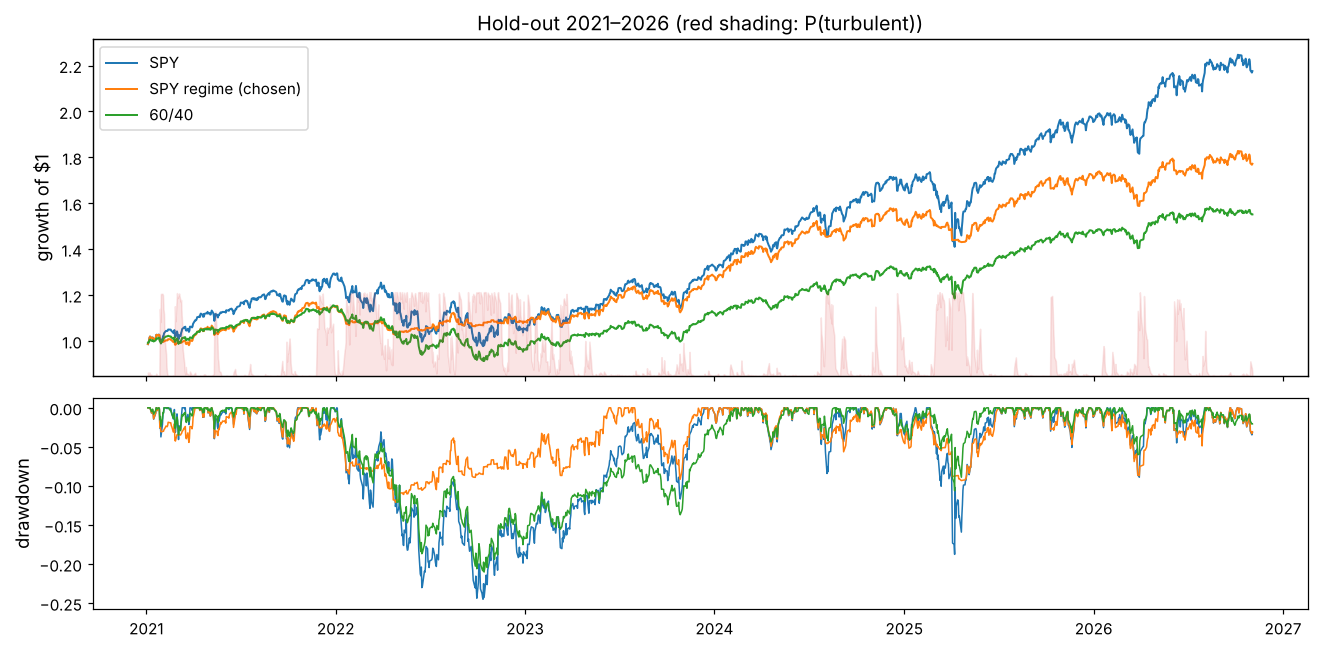

In [13]:
final, e_final = spy_regime(filt, best["floor"], best["band"])
hold_tab = pd.DataFrame({"SPY": perf(rets["SPY"].loc[HOLD]), "SPY vol-targeted": perf(vt.loc[HOLD]), "60/40": perf(b6040.loc[HOLD]),
                         "SPY regime (chosen)": perf(final.loc[HOLD])}).T
yrs = len(final.loc[HOLD]) / 252
hold_tab["turnover / year"] = [0, e_vt.loc[HOLD].diff().abs().sum() / yrs, 0, e_final.loc[HOLD].diff().abs().sum() / yrs]
print(hold_tab.round(3))
h = hold_tab
R.update(ho_spy=f"{h.loc['SPY', 'Sharpe (excess)']:.2f}", ho_reg=f"{h.loc['SPY regime (chosen)', 'Sharpe (excess)']:.2f}",
         ho_spy_dd=f"{h.loc['SPY', 'max drawdown']:.0%}", ho_reg_dd=f"{h.loc['SPY regime (chosen)', 'max drawdown']:.0%}",
         ho_spy_ret=f"{h.loc['SPY', 'annual return']:.1%}", ho_reg_ret=f"{h.loc['SPY regime (chosen)', 'annual return']:.1%}",
         ho_6040=f"{h.loc['60/40', 'Sharpe (excess)']:.2f}", ho_vt=f"{h.loc['SPY vol-targeted', 'Sharpe (excess)']:.2f}")
passed = (h.loc["SPY regime (chosen)", "Sharpe (excess)"] >= h.loc["SPY", "Sharpe (excess)"]) and (h.loc["SPY regime (chosen)", "max drawdown"] > h.loc["SPY", "max drawdown"])
R["verdict"] = "passes" if passed else "does not pass"

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for name, s in [("SPY", rets["SPY"]), ("SPY regime (chosen)", final), ("60/40", b6040)]:
    eq = (1 + s.loc[HOLD].fillna(0)).cumprod(); ax[0].plot(eq, lw=1.3, label=name)
    ax[1].plot(eq / eq.cummax() - 1, lw=1)
ax2 = ax[0].twinx(); ax2.fill_between(filt.loc[HOLD].index, 0, filt.loc[HOLD], color="tab:red", alpha=0.12); ax2.set_ylim(0, 4); ax2.set_yticks([])
ax[0].set_ylabel("growth of $1"); ax[0].legend(); ax[0].set_title("Hold-out 2021–2026 (red shading: P(turbulent))"); ax[1].set_ylabel("drawdown")
save_fig("holdout"); plt.show()

![Figure 10-3. The single hold-out test. The regime strategy steps aside during the 2022 bear market and the 2025 sell-off (red shading), roughly halving SPY's drawdowns, but it also misses part of each rebound, so its return is lower.](images/holdout.png)

On the hold-out, the regime strategy has a Sharpe ratio of 0.68 against 0.69 for SPY, and a maximum drawdown of -12% against -24%. It earned 10.4% a year against SPY's 14.8%: the same reward per unit of risk, with about half the risk. By the plan's pre-registered criteria the strategy **does not pass** the hold-out test: its Sharpe ratio is 0.68, a hair below SPY's 0.69, and the plan said “not below”. The drawdown criterion was met easily.

This is the moment the research plan exists for. A difference of 0.01 in a Sharpe ratio over six years is pure noise, and it would be very easy to say “essentially equal, so it passes”, or to notice that a floor of 0.25 would have done better on the hold-out and switch to it. Both are moving the goalposts after seeing the answer, and once you allow yourself that, the hold-out is no longer a test. The honest conclusion is narrower and still useful: **the regime signal's risk reduction was confirmed out of sample (the drawdown halved); its development-period advantage in risk-adjusted return was not.** Notice also that the simplest benchmark, volatility targeting, had the best hold-out Sharpe ratio (0.77). A model of hidden market moods adds less than its elegance suggests over a rule that just reacts to recent volatility.

## Present your solution: an automatically generated research report

A research result that lives only in a notebook gets lost. The pipeline writes its own report, with every number taken from the computations above, so the report can never disagree with the code.

In [14]:
def md_table(df, fmt="{:.3f}"):
    cols = [""] + list(df.columns)
    rows = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for i, r_ in df.iterrows():
        rows.append("| " + " | ".join([str(i)] + [fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r_]) + " |")
    return "\n".join(rows)

report = f"""# Research report: regime-aware SPY exposure

*Generated by the Chapter 10 notebook from data up to {px.index[-1]:%Y-%m-%d}. Plan: `research_plan.json` (written before testing).*

## Summary
A two-state Gaussian hidden Markov model on daily SPY returns, refitted every January and used only through forward-filtered
probabilities, sets the SPY exposure to 1 − P(turbulent) (floor {best['floor']:g}, no-trade band {best['band']:g}, 2 bps costs).

* **Hypothesis 1 (SPY):** development Sharpe {best['sharpe']:.2f} vs SPY {dev_tab.loc['SPY', 'Sharpe (excess)']:.2f}; deflated Sharpe ratio {dsr:.3f} over 9 variants.
  Hold-out: Sharpe {h.loc['SPY regime (chosen)', 'Sharpe (excess)']:.2f} vs {h.loc['SPY', 'Sharpe (excess)']:.2f}, max drawdown {h.loc['SPY regime (chosen)', 'max drawdown']:.0%} vs {h.loc['SPY', 'max drawdown']:.0%}. **Verdict: {R['verdict']} the pre-registered test.**
* **Hypothesis 2 (diversified ETF portfolio):** rejected on the development period (Sharpe {h2_tab.iloc[2, 2]:.2f} → {h2_tab.iloc[3, 2]:.2f} with the regime overlay).
* **Look-ahead check:** smoothed full-sample probabilities would have shown a development Sharpe of {trap.iloc[1, 2]:.2f}; all results use filtered walk-forward probabilities.

## Development period 2007–2020
{md_table(dev_tab)}

## Hold-out 2021–2026 (run once)
{md_table(hold_tab)}

## Risks and limitations
* Few independent regime episodes (2008, 2011, 2015–16, 2018, 2020, 2022, 2025); the Sharpe difference vs SPY is not statistically reliable.
* The filter reacts after turbulence starts; sharp one-day crashes (October 1987) would be missed entirely.
* Execution assumes market-on-close orders at the closing price; T-bills as the cash asset; no taxes.
"""
Path("report.md").write_text(report)
print(report[:1500])

# Research report: regime-aware SPY exposure

*Generated by the Chapter 10 notebook from data up to 2026-11-03. Plan: `research_plan.json` (written before testing).*

## Summary
A two-state Gaussian hidden Markov model on daily SPY returns, refitted every January and used only through forward-filtered
probabilities, sets the SPY exposure to 1 − P(turbulent) (floor 0, no-trade band 0.1, 2 bps costs).

* **Hypothesis 1 (SPY):** development Sharpe 0.76 vs SPY 0.50; deflated Sharpe ratio 0.993 over 9 variants.
  Hold-out: Sharpe 0.68 vs 0.69, max drawdown -12% vs -24%. **Verdict: does not pass the pre-registered test.**
* **Hypothesis 2 (diversified ETF portfolio):** rejected on the development period (Sharpe 0.76 → 0.46 with the regime overlay).
* **Look-ahead check:** smoothed full-sample probabilities would have shown a development Sharpe of 1.72; all results use filtered walk-forward probabilities.

## Development period 2007–2020
|  | annual return | vol | Sharpe (excess) | max drawdo

## Launch, monitor and maintain: a paper-trading loop

The last step turns the research into a system that runs every trading day without anyone touching it. The module `paper_trader/paper_trade.py` is production-style code, independent of this notebook: it loads prices, refits the HMM each January, runs the forward filter, decides the exposure, sends a (simulated) market-on-close order, and appends a row to a ledger. It is idempotent, so running it twice on the same day does nothing.

In [15]:
print(Path("paper_trader/config.json").read_text())
src = Path("paper_trader/paper_trade.py").read_text()
print(src[src.index("# ---------------------------------------------------------------- one trading day"):src.index("def run(")])

{
  "ticker": "SPY",
  "first_data": "2003-01-01",
  "floor": 0.0,
  "band": 0.1,
  "cost_bps": 2.0,
  "initial_capital": 1000000
}

# ---------------------------------------------------------------- one trading day
def trade_day(date, prices, last, params_path):
    tk, cfg = CONFIG["ticker"], CONFIG
    px = prices.loc[:date]
    close = float(px[tk].iloc[-1])
    cash, shares, exposure = (last["cash"], last["shares"], last["exposure"]) if last is not None else (cfg["initial_capital"], 0, 0.0)
    if last is not None:                                           # interest on cash since the previous close
        cash *= (1 + float(px["TBILL"].iloc[-2]) / 100 / 252) if cash > 0 else 1.0   # rate known the day before
    nav = cash + shares * close
    x = np.log(px[tk]).diff().dropna()
    p_turb = filter_last(100 * x.to_numpy(), params_for_year(date.year, x, params_path))
    target = 1 - (1 - cfg["floor"]) * p_turb
    if last is None or abs(target - exposure) > cfg["band"]:
        e

Before trusting it with paper money, **replay** history through it day by day, as if it were live, and **reconcile** the result with the vectorised backtest. Two independent implementations that agree are the best test either can have (Chapter 2 did the same with a loop and a vectorised backtester).

In [16]:
sys.path.insert(0, "paper_trader")
import paper_trade
led_path, par_path = Path("paper_trader/replay_ledger.csv"), Path("paper_trader/replay_params.json")
led_path.unlink(missing_ok=True); par_path.unlink(missing_ok=True)
t0 = time.perf_counter()
ledger = paper_trade.run(replay_csv=str(DATA / "capstone_daily.csv"), start="2026-01-02", ledger_path=str(led_path), params_path=str(par_path))
print(f"replayed {len(ledger)} trading days in {time.perf_counter() - t0:.0f} s")
print(ledger.tail(6).to_string(index=False))

ledger["date"] = pd.to_datetime(ledger["date"]); live = ledger.set_index("date")["nav"].pct_change().dropna()
bt = final.reindex(live.index)
gap = (live - bt)
print(f"reconciliation over {len(gap)} days: mean daily difference {1e4 * gap.mean():+.2f} bps, std {1e4 * gap.std():.2f} bps, "
      f"cumulative {1e4 * ((1 + live).prod() - (1 + bt).prod()):+.1f} bps; exposure correlation {ledger.set_index('date')['exposure'].corr(e_final.reindex(ledger['date'])):.4f}")
R.update(rec_mean=f"{1e4 * gap.mean():+.2f}", rec_sd=f"{1e4 * gap.std():.2f}", rec_cum=f"{1e4 * ((1 + live).prod() - (1 + bt).prod()):+.1f}", rec_n=len(gap))
led_path.unlink(missing_ok=True); par_path.unlink(missing_ok=True)

replayed 211 trading days in 5 s
      date  close  p_turbulent  exposure  shares  trade  cost      cash        nav
2026-10-27 769.66     0.011077  0.975344    1338      0  0.00  26329.80 1056134.88
2026-10-28 772.31     0.008082  0.975344    1338      0  0.00  26334.03 1059684.81
2026-10-29 769.36     0.008560  0.975344    1338      0  0.00  26338.22 1055741.90
2026-10-30 755.72     0.179324  0.820676    1126   -212 32.04 186523.00 1037463.72
2026-11-02 752.10     0.094939  0.820676    1127      1  0.15 185800.28 1033416.98
2026-11-03 754.35     0.037722  0.962278    1321    194 29.27  39456.82 1035953.17
reconciliation over 210 days: mean daily difference -0.03 bps, std 1.11 bps, cumulative +4.9 bps; exposure correlation 0.9983


Over 210 replayed days of 2026, the paper trader and the backtest differ by -0.03 basis points a day on average (standard deviation 1.11), +4.9 basis points in total. Every difference must be explained, and here they are: the trader holds whole shares, rebalances its share count daily to keep the exposure constant (paying costs on those small trades, which the backtest ignores), and earns interest only on its actual cash. Any difference that cannot be explained this way is a bug in one of the two.

- **Schedule it.** Run `python3 paper_trader/paper_trade.py` every trading day at about 15:50 New York time, for example with `cron` on a small server or a scheduled GitHub Actions workflow that commits the ledger. Keep the ledger and the HMM parameters under version control.
- **Monitor it daily.** Alarm if the data are stale (the last price is not today's), if the daily reconciliation gap exceeds a few basis points, if the exposure changes by more than 0.5 in a day, or if the drawdown exceeds 1.5 times the worst drawdown of the backtest.
- **Maintain it.** The HMM is refitted every January automatically; review each refit (a turbulent state whose volatility suddenly halves means the model has redefined its states). Re-run the whole notebook, including the research plan, before changing anything.
- **Go live only after months of paper trading**, and only with a broker's API that supports market-on-close orders and position checks.

## Try it out

::playground animations/regime_lab.html 740

Two tabs: the regime strategy on real SPY data from 2007, where you can switch between filtered and smoothed probabilities and choose the exposure in the turbulent state and the cost; and a hidden-Markov simulator in which you set the persistence of the two states and their volatilities and watch how quickly, and how reliably, the filter detects a change of regime.

## Exercises

:::exercise
1. **Three states.** Extend `fit_hmm` to $K$ states and fit $K = 3$ to SPY. Is the third state a “crash” state or a “recovery” state? Compare the models with the Bayesian information criterion $\text{BIC} = -2\log L + k\log T$, with $k$ the number of free parameters.
2. **Detection delay.** In the simulator of the HMM section, measure the average number of days between the true switch into the turbulent state and the first day the filtered probability exceeds 0.5. How does it depend on the ratio of the two volatilities?
3. **Add VIX.** Use a bivariate observation (SPY return, daily change in log VIX) with a two-dimensional normal per state. Does the filter detect turbulence earlier? Respect the plan: test it on the development period only.
4. **Costs and capacity.** Using the square-root law of Chapter 9 and SPY's ADV, at what fund size does the regime strategy's annual cost reach one quarter of its development-period excess return?
5. **A second plan.** Write a research plan (in the format of `research_plan.json`) for a strategy idea of your own from this course, including the hold-out period, the number of variants and the success criteria, *before* writing any code. Then run it.
:::

<details><summary>Solutions</summary>

In [17]:
# 2
def detection_delay(vol_ratio, n=20_000, seed=0):
    rg = np.random.default_rng(seed); p = dict(mu=np.array([0.05, -0.05]), sd=np.array([0.8, 0.8 * vol_ratio]),
                                               A=np.array([[0.99, 0.01], [0.03, 0.97]]), pi=np.array([1.0, 0.0]))
    z = np.zeros(n, int)
    for t in range(1, n):
        z[t] = rg.random() < p["A"][z[t - 1], 1]
    x = rg.normal(p["mu"][z], p["sd"][z]); pr = forward_filter(x, p)[:, 1]
    starts = np.flatnonzero((z[1:] == 1) & (z[:-1] == 0)) + 1; delays = []
    for s in starts:
        end = s
        while end < n and z[end] == 1:
            end += 1
        hit = np.flatnonzero(pr[s:end] > 0.5)
        delays.append(hit[0] if len(hit) else np.nan)
    d_ = np.array(delays, float)
    return np.nanmean(d_), np.isnan(d_).mean()
for vr in [1.5, 2, 3, 4]:
    m, miss = detection_delay(vr)
    print(f"vol ratio {vr}: average delay {m:.1f} days, turbulent spells never detected {miss:.0%}")

# 4
adv_dollars = 85e6 * px["SPY"].iloc[-1]                     # SPY trades roughly 60-100 million shares a day
sigma_d = rets["SPY"].loc[DEV].std(); excess = best["returns"].mean() * 252; turnover = best["turnover"]
for aum in [1e8, 1e9, 1e10, 5e10]:
    trade = aum * turnover / 52                              # rough size of a typical rebalancing trade (about weekly)
    cost_per_unit = 0.7 * sigma_d * np.sqrt(trade / adv_dollars)
    print(f"fund ${aum / 1e9:.1f}bn: cost {1e4 * cost_per_unit * turnover:.1f} bps a year vs excess return {1e4 * excess:.0f} bps")

vol ratio 1.5: average delay 7.7 days, turbulent spells never detected 20%
vol ratio 2: average delay 4.4 days, turbulent spells never detected 9%


vol ratio 3: average delay 2.2 days, turbulent spells never detected 7%


vol ratio 4: average delay 1.3 days, turbulent spells never detected 2%
fund $0.1bn: cost 19.0 bps a year vs excess return 756 bps
fund $1.0bn: cost 60.1 bps a year vs excess return 756 bps
fund $10.0bn: cost 190.1 bps a year vs excess return 756 bps
fund $50.0bn: cost 425.1 bps a year vs excess return 756 bps


The more the turbulent state's volatility differs from the calm one's, the sooner the filter notices: with a ratio of 3 the delay is about two days, with a ratio of 1.5 it is about a week and a fifth of the turbulent spells are never detected at all. For capacity, with these rough assumptions the cost reaches a quarter of the excess return at around 10 billion dollars: a strategy that trades one extremely liquid ETF can be large, but it is not unlimited, and strategies on small stocks reach the same point thousands of times sooner.

</details>

## Where to go from here

This is the end of the course. You started from “what is money?” and have built, from scratch, the statistics of returns, a backtester, volatility models, portfolio optimisers, leak-free machine-learning validation, factor models, pairs trading, option pricers and a neural surrogate, execution algorithms and market makers, and now a full research pipeline with a paper-trading loop.

- **Books.** López de Prado, *Advances in Financial Machine Learning* (2018); Bouchaud, Bonart, Donier and Gould, *Trades, Quotes and Prices* (2018); Gatheral, *The Volatility Surface* (2006); Ilmanen, *Expected Returns* (2011); Hull, *Options, Futures and Other Derivatives*.
- **Data.** Point-in-time equity data (CRSP, Compustat through a university), order-book data (LOBSTER for Nasdaq), and option data (OptionMetrics), to repeat these projects without the survivorship and snapshot limitations of free data.
- **Practice.** Take one chapter's project and replace its data with a market you know. Write the research plan first.

In [18]:
# data for the playground: SPY returns, filtered and smoothed probabilities, T-bill
Path("animations").mkdir(exist_ok=True)
idx = filt.index
payload = {"dates": [d.strftime("%Y-%m-%d") for d in idx],
           "r": [round(float(v), 6) for v in rets["SPY"].reindex(idx).fillna(0)],
           "pf": [round(float(v), 4) for v in filt], "ps": [round(float(v), 4) for v in smooth.reindex(idx)],
           "rf": [round(float(v), 7) for v in rf.reindex(idx).fillna(0)],
           "fit": {"mu": [round(float(v), 4) for v in p_dev["mu"]], "sd": [round(float(v), 4) for v in p_dev["sd"]],
                   "A": [[round(float(v), 5) for v in row] for row in p_dev["A"]]}}
Path("animations/data.js").write_text("window.REGIME_DATA = " + json.dumps(payload) + ";\n")
print(len(idx))

4989
